In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

# dataset loading

### Synthetic Data

In [2]:
synthetic_train = pd.read_csv('anthrax_decision_support_data.csv')
synthetic_train.head()

,Fever,Convulsions,Resp_Cardiac_Distress,Rumination Cessation,Milk Production Loss,Abortion,Bloody_Discharge,Edema,Reduced_Appetite,Lethargy,Staggering,Somnolence,Recumbence,Trembling,Anthrax
0,0,0,0,1,1,1,1,0,0,1,0,1,0,1,0
1,1,0,0,1,1,0,0,1,0,1,0,1,0,1,1
2,1,0,1,1,1,0,0,0,1,0,1,0,0,0,1
3,1,0,1,1,1,0,1,1,0,1,0,0,0,1,1
4,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0


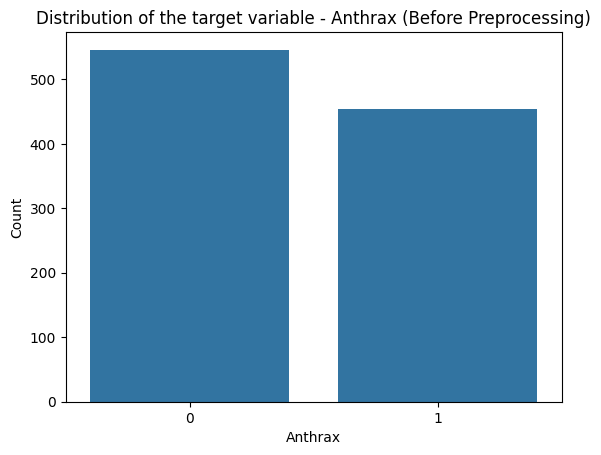

Anthrax
0    546
1    454
Name: count, dtype: int64


In [7]:
sns.countplot(x='Anthrax', data=synthetic_train)
plt.title('Distribution of the target variable - Anthrax (Before Preprocessing)')
plt.xlabel('Anthrax')
plt.ylabel('Count')
plt.show()

print(synthetic_train['Anthrax'].value_counts())

In [8]:
# duplicate data
duplicate_data = synthetic_train.duplicated().sum()
print(duplicate_data)

176


In [9]:
synthetic_train = synthetic_train.drop_duplicates()

In [10]:
print("total rows:", len(synthetic_train))

total rows: 824


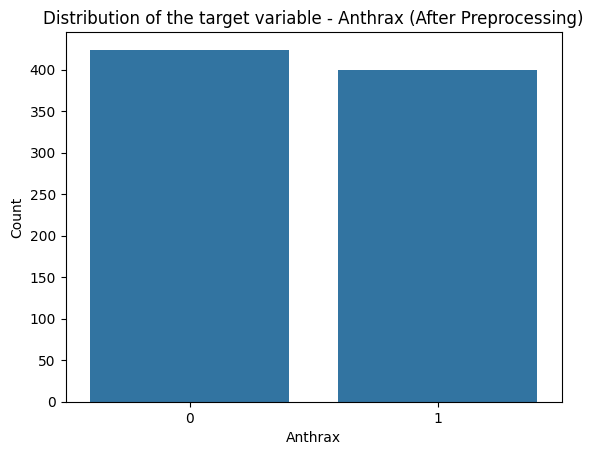

Anthrax
0    424
1    400
Name: count, dtype: int64


In [11]:
sns.countplot(x="Anthrax", data=synthetic_train)
plt.title('Distribution of the target variable - Anthrax (After Preprocessing)')
plt.xlabel('Anthrax')
plt.ylabel('Count')
plt.show()

print(synthetic_train['Anthrax'].value_counts())

### Field Data

In [12]:
field_test = pd.read_csv("Anthrax field data updated.csv")
field_test.head(3)

,Fever,Convulsions,Resp_Cardiac_Distress,Rumination Cessation,Milk Production Loss,Abortion,Bloody_Discharge,Edema,Reduced_Appetite,Lethargy,Staggering,Somnolence,Recumbence,Trembling,Anthrax
0,1,1,0,1,1,0,0,0,1,0,1,0,1,1,1
1,1,1,1,1,0,0,0,0,1,0,1,0,0,1,1
2,1,1,0,1,1,1,1,1,0,0,1,0,1,1,1


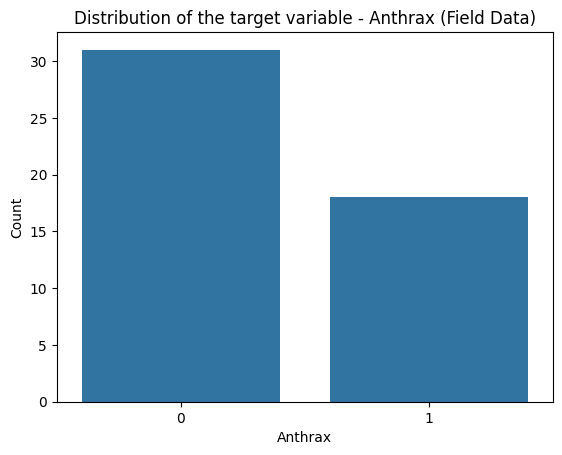

Anthrax
0    31
1    18
Name: count, dtype: int64


In [13]:
sns.countplot(x='Anthrax', data=field_test)
plt.title('Distribution of the target variable - Anthrax (Field Data)')
plt.xlabel('Anthrax')
plt.ylabel('Count')
plt.show()

print(field_test['Anthrax'].value_counts())

In [14]:
duplicate_data = field_test.duplicated().sum()
print(duplicate_data)

1


In [15]:
field_test = field_test.drop_duplicates()

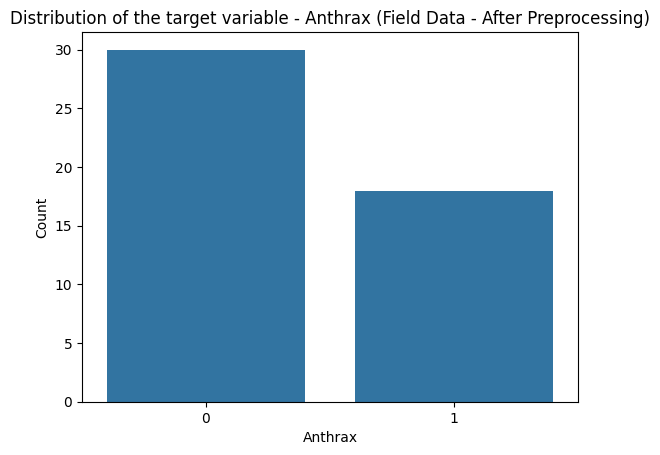

Anthrax
0    30
1    18
Name: count, dtype: int64


In [16]:
sns.countplot(x='Anthrax', data=field_test)
plt.title('Distribution of the target variable - Anthrax (Field Data - After Preprocessing)')
plt.xlabel('Anthrax')
plt.ylabel('Count')
plt.show()

print(field_test['Anthrax'].value_counts())

## Model Part

In [18]:
synthetic_train[synthetic_train.columns] = synthetic_train[synthetic_train.columns].astype('float64')

C:\Users\USER\AppData\Local\Temp\ipykernel_19120\3332420734.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  synthetic_train[synthetic_train.columns] = synthetic_train[synthetic_train.columns].astype('float64')


In [19]:
synthetic_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 824 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Fever                  824 non-null    float64
 1   Convulsions            824 non-null    float64
 2   Resp_Cardiac_Distress  824 non-null    float64
 3   Rumination Cessation   824 non-null    float64
 4   Milk Production Loss   824 non-null    float64
 5   Abortion               824 non-null    float64
 6   Bloody_Discharge       824 non-null    float64
 7   Edema                  824 non-null    float64
 8   Reduced_Appetite       824 non-null    float64
 9   Lethargy               824 non-null    float64
 10  Staggering             824 non-null    float64
 11  Somnolence             824 non-null    float64
 12  Recumbence             824 non-null    float64
 13  Trembling              824 non-null    float64
 14  Anthrax                824 non-null    float64
dtypes: float64(

In [24]:
x = synthetic_train.iloc[: , [0,1,2,3,4,5,6,7,8,9,10,11,12,13]]
y = synthetic_train.iloc[: , -1]

In [21]:
field_test[field_test.columns] = field_test[field_test.columns].astype('float64')

In [22]:
field_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48 entries, 0 to 48
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Fever                  48 non-null     float64
 1   Convulsions            48 non-null     float64
 2   Resp_Cardiac_Distress  48 non-null     float64
 3   Rumination Cessation   48 non-null     float64
 4   Milk Production Loss   48 non-null     float64
 5   Abortion               48 non-null     float64
 6   Bloody_Discharge       48 non-null     float64
 7   Edema                  48 non-null     float64
 8   Reduced_Appetite       48 non-null     float64
 9   Lethargy               48 non-null     float64
 10  Staggering             48 non-null     float64
 11  Somnolence             48 non-null     float64
 12  Recumbence             48 non-null     float64
 13  Trembling              48 non-null     float64
 14  Anthrax                48 non-null     float64
dtypes: float64(15

In [59]:
x_test = field_test.iloc[: , [0,1,2,3,4,5,6,7,8,9,10,11,12,13]]
y_test = field_test.iloc[: , -1]

In [92]:
from sklearn.model_selection import train_test_split

x_train, x_dev, y_train, y_dev = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

### Using RF

In [ ]:
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best Parameters Found: {'classifier__class_weight': None, 'classifier__criterion': 'gini', 'classifier__max_depth': 6, 'classifier__max_features': 'log2', 'classifier__min_samples_split': 6, 'classifier__n_estimators': 291, 'classifier__random_state': 42}
Best Cross-Validation Accuracy: 0.9686579131652661

In [100]:
from sklearn.ensemble import RandomForestClassifier
# using cv = 5
rf = RandomForestClassifier(
    class_weight = None,
    criterion = 'gini',
    max_depth = 6,
    max_features = 'log2',
    min_samples_split = 6,
    n_estimators = 291,
    random_state=42)

In [101]:
rf.fit(x_train, y_train)

RandomForestClassifier(max_depth=6, max_features='log2', min_samples_split=6,
                       n_estimators=291, random_state=42)

In [77]:
# from sklearn.metrics import roc_curve

# y_prob = rf.predict_proba(x_dev)[:, 1]
# fpr, tpr, thresholds = roc_curve(y_dev, y_prob)

# # Youden's J statistic = Sensitivity + Specificity - 1 = TPR - FPR
# j_scores = tpr - fpr
# best_idx = np.argmax(j_scores)
# best_threshold = thresholds[best_idx]

# print(f"Best threshold by Youden's J: {best_threshold:.4f}")
# print(f"Youden's J score: {j_scores[best_idx]:.4f}")

In [113]:
y_prob = rf.predict_proba(x_test)[:, 1]

In [122]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       1.00      0.57      0.72        30
         1.0       0.58      1.00      0.73        18

    accuracy                           0.73        48
   macro avg       0.79      0.78      0.73        48
weighted avg       0.84      0.73      0.73        48

[[17 13]
 [ 0 18]]


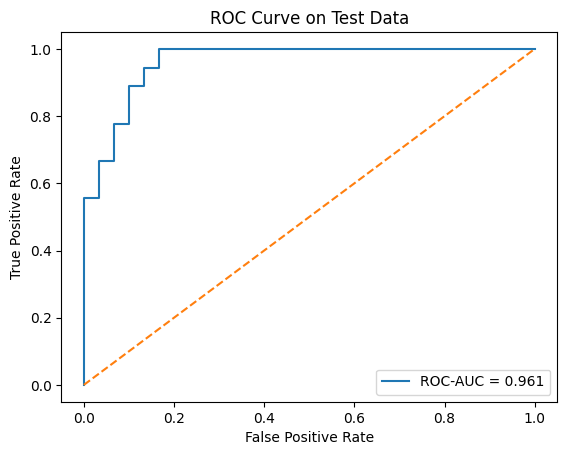

In [120]:
from sklearn.metrics import roc_curve, roc_auc_score


# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# AUC
auc = roc_auc_score(y_test, y_prob)

# Plot
plt.plot(fpr, tpr, label=f"ROC-AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Test Data")
plt.legend()
plt.show()

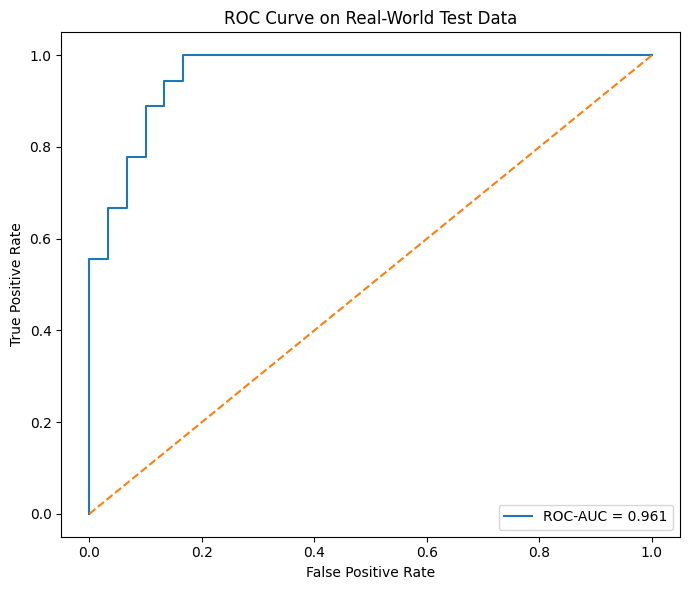

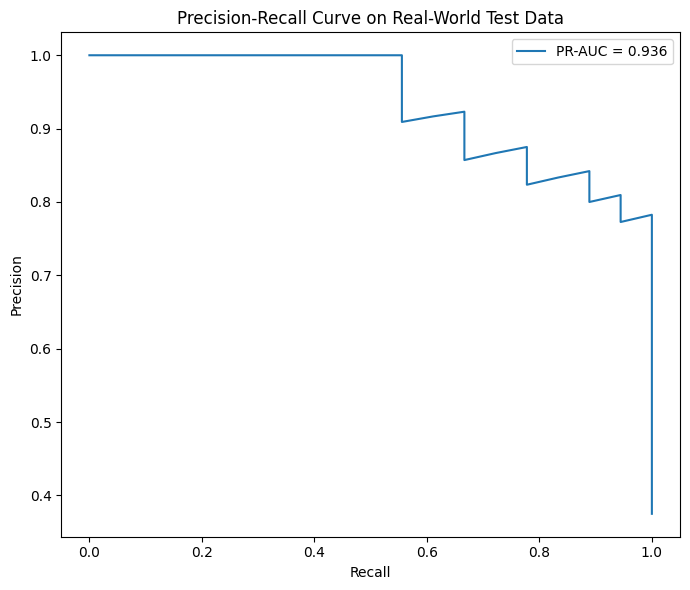

ROC-AUC: 0.961
PR-AUC:  0.936


In [121]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# Predicted probabilities on real-world test data
y_prob_real = rf.predict_proba(x_test)[:, 1]

# =========================
# ROC-AUC
# =========================
fpr, tpr, _ = roc_curve(y_test, y_prob_real)
roc_auc = roc_auc_score(y_test, y_prob_real)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Real-World Test Data")
plt.legend()
plt.tight_layout()
plt.show()


# =========================
# PR-AUC
# =========================
precision, recall, _ = precision_recall_curve(y_test, y_prob_real)
pr_auc = average_precision_score(y_test, y_prob_real)

plt.figure(figsize=(7, 6))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve on Real-World Test Data")
plt.legend()
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.3f}")
print(f"PR-AUC:  {pr_auc:.3f}")

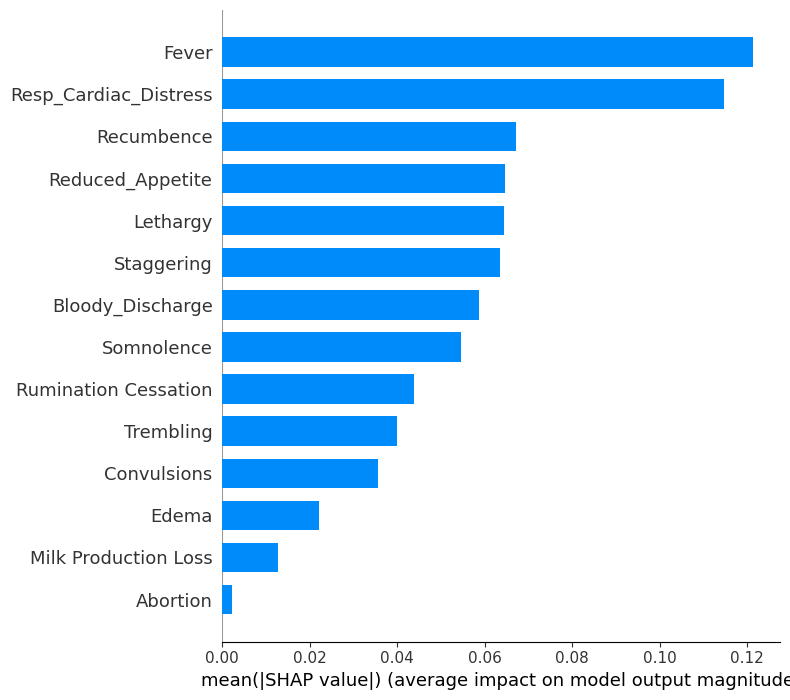

In [98]:
import shap

explainer = shap.TreeExplainer(rf)

# SHAP values
shap_values = explainer.shap_values(x_test)

# Handle both SHAP versions safely
if isinstance(shap_values, list):
    # Binary classification → use class 1
    rf = shap_values[1]
else:
    # New versions sometimes return (n_samples, n_features, n_classes)
    rf = shap_values[:, :, 1]

# Global summary plot
shap.summary_plot(rf, x_test, plot_type="bar")


In [102]:
y_prob_syn = rf.predict_proba(x_dev)[:, 1]
y_prob_real = rf.predict_proba(x_test)[:, 1]

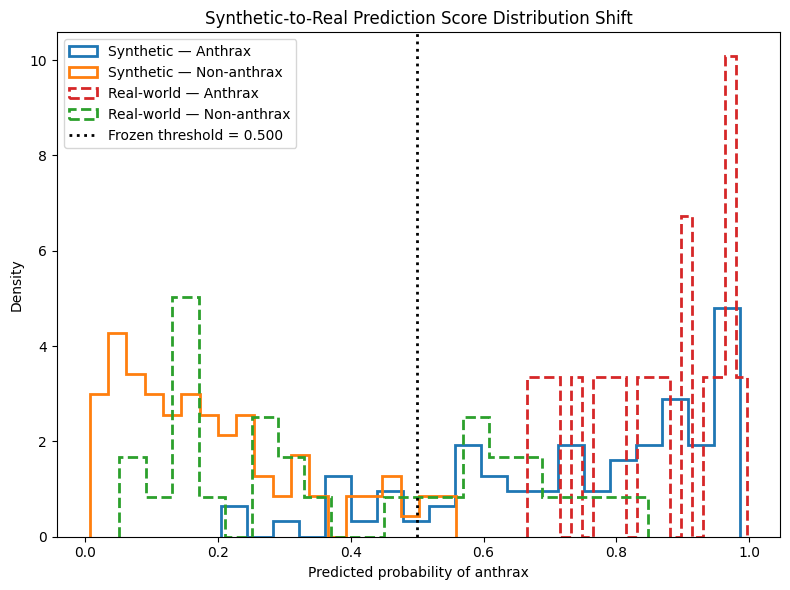

In [112]:
plt.figure(figsize=(8, 6))

# Synthetic — Anthrax
plt.hist(
    y_prob_syn[y_dev == 1],
    bins=20,
    density=True,
    histtype="step",
    linewidth=2,
    linestyle="-",
    color="tab:blue",
    label="Synthetic — Anthrax"
)

# Synthetic — Non-anthrax
plt.hist(
    y_prob_syn[y_dev == 0],
    bins=20,
    density=True,
    histtype="step",
    linewidth=2,
    linestyle="-",
    color="tab:orange",
    label="Synthetic — Non-anthrax"
)

# Real-world — Anthrax
plt.hist(
    y_prob_real[y_test == 1],
    bins=20,
    density=True,
    histtype="step",
    linewidth=2,
    linestyle="--",
    color="tab:red",
    label="Real-world — Anthrax"
)

# Real-world — Non-anthrax
plt.hist(
    y_prob_real[y_test == 0],
    bins=20,
    density=True,
    histtype="step",
    linewidth=2,
    linestyle="--",
    color="tab:green",
    label="Real-world — Non-anthrax"
)

# Frozen threshold
threshold = 0.5

plt.axvline(
    threshold,
    color="black",
    linestyle=":",
    linewidth=2,
    label=f"Frozen threshold = {threshold:.3f}"
)

plt.xlabel("Predicted probability of anthrax")
plt.ylabel("Density")
plt.title("Synthetic-to-Real Prediction Score Distribution Shift")

plt.legend()
plt.tight_layout()
plt.show()

## Hyper-parameter Tuning

In [70]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('classifier', RandomForestClassifier(random_state=42))
])

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform


param_dist = {
    'classifier__n_estimators': randint(100, 401),       
    'classifier__max_depth': randint(3, 16),             
    'classifier__max_features': ['sqrt','log2', 3, 5, 8, 10, None],         
    'classifier__min_samples_split': randint(2, 11),
    'classifier__class_weight': [None, 'balanced','balanced_subsample'],
    'classifier__criterion': ['gini', 'entropy', 'log_loss'],
    'classifier__random_state': [42] 
}


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=100,                
    cv=cv,
    scoring='roc_auc',  # choose roc_auc or accuracy........both showing similar results paul
    n_jobs=-1,
    verbose=2,
    random_state=42,
    return_train_score=True
)

random_search.fit(x, y)

print("Best Parameters Found:", random_search.best_params_)
print("Best Cross-Validation Roc-AUC:", random_search.best_score_)

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best Parameters Found: {'classifier__class_weight': None, 'classifier__criterion': 'gini', 'classifier__max_depth': 6, 'classifier__max_features': 'log2', 'classifier__min_samples_split': 6, 'classifier__n_estimators': 291, 'classifier__random_state': 42}
Best Cross-Validation Accuracy: 0.9686579131652661
